**Live Deployment Link:** [Open the Heart Disease Prediction System app](https://ml-lab-assignment-tbdhtsrxjgmpyfxc2vxktl.streamlit.app/)

**Name:** Mubashir Ali  
**Registration No.:** fa24-bse-140

# Heart Disease Prediction System

## 1. Import Libraries

In [1]:
import pandas as pd
import pickle
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

## 2. Load Data

Use sample-data.csv, prepared from the UCI Cleveland Heart Disease dataset. Only four input attributes are selected: Sex, ChestPain, RestECG and ExerciseAngina. Source: https://archive.ics.uci.edu/dataset/45/heart+disease. This is an educational model.

Keep this notebook and its sample-data.csv in the same folder.

In [2]:
data = pd.read_csv("sample-data.csv")
print(data.head())
print("Rows:", len(data))

      Sex         ChestPain         RestECG ExerciseAngina HeartDisease
0    Male    Typical Angina  LV Hypertrophy             No           No
1    Male      Asymptomatic  LV Hypertrophy            Yes          Yes
2    Male      Asymptomatic  LV Hypertrophy            Yes          Yes
3    Male  Non-Anginal Pain          Normal             No           No
4  Female   Atypical Angina  LV Hypertrophy             No           No
Rows: 303


## 3. Understand and Clean Data

In [3]:
print(data.isnull().sum())
print(data['HeartDisease'].value_counts())
data = data.dropna().copy()

Sex               0
ChestPain         0
RestECG           0
ExerciseAngina    0
HeartDisease      0
dtype: int64
HeartDisease
No     164
Yes    139
Name: count, dtype: int64


## 4. Select Four Input Attributes

In [4]:
features = ['Sex', 'ChestPain', 'RestECG', 'ExerciseAngina']
target = 'HeartDisease'
data = data[features + [target]]

## 5. Label Encoding

In [5]:
encoded = data.copy()
encoders = {}

for column in data.columns:
    encoder = LabelEncoder()
    encoded[column] = encoder.fit_transform(data[column])
    encoders[column] = encoder

encoded.to_csv("sample-data-encoded.csv", index=False)
print(encoded.head())

   Sex  ChestPain  RestECG  ExerciseAngina  HeartDisease
0    1          3        0               0             0
1    1          0        0               1             1
2    1          0        0               1             1
3    1          2        1               0             0
4    0          1        0               0             0


## 6. Training Phase

Use 80% of the data for training and 20% for testing.

In [6]:
training, testing = train_test_split(
    encoded, test_size=0.2, random_state=0, stratify=encoded["HeartDisease"]
)

training.to_csv("training-data-encoded.csv", index=False)
testing.to_csv("testing-data-encoded.csv", index=False)

X_train = training[features]
y_train = training[target]
X_test = testing[features]
y_test = testing[target]

model = SVC(gamma="auto", random_state=0)
model.fit(X_train, y_train)

with open('heart_svc_trained_model.pkl', "wb") as file:
    pickle.dump(model, file)

## 7. Testing Phase

Accuracy: 0.82
              precision    recall  f1-score   support

          No       0.76      0.97      0.85        33
         Yes       0.95      0.64      0.77        28

    accuracy                           0.82        61
   macro avg       0.85      0.81      0.81        61
weighted avg       0.85      0.82      0.81        61



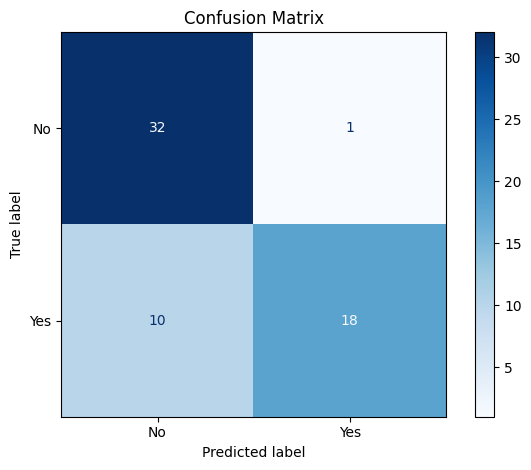

In [7]:
with open('heart_svc_trained_model.pkl', "rb") as file:
    model = pickle.load(file)

predictions = model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)
print("Accuracy:", round(accuracy, 2))
print(classification_report(y_test, predictions, target_names=encoders[target].classes_))

results = testing.copy()
results["Predictions"] = predictions
results.to_csv("model-predictions.csv", index=False)

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions, display_labels=encoders[target].classes_, cmap="Blues"
)
plt.title("Confusion Matrix")
plt.tight_layout()
plt.show()

## 8. Application Phase

Edit the example values below to test another passenger or patient.

In [8]:
example = pd.DataFrame([['Male', 'Asymptomatic', 'Normal', 'Yes']], columns=features)
example_encoded = example.copy()

for column in features:
    example_encoded[column] = encoders[column].transform(example[column])

prediction = model.predict(example_encoded)
print("Prediction:", encoders[target].inverse_transform(prediction)[0])

Prediction: Yes


## 9. Feedback Phase

Ask users to review the predictions. These are suggested improvements, not collected user feedback.

In [9]:
improvements = ['Use cross-validation with the same four attributes.', 'Compare SVC with other classifiers.']

for item in improvements:
    print(item)

Use cross-validation with the same four attributes.
Compare SVC with other classifiers.


## 10. Cloud Deployment

The Streamlit app is available at [https://ml-lab-assignment-tbdhtsrxjgmpyfxc2vxktl.streamlit.app/](https://ml-lab-assignment-tbdhtsrxjgmpyfxc2vxktl.streamlit.app/).

- **Repository:** https://github.com/thismubashir/ML-LAB-Assignment
- **Branch:** main
- **Main file path:** `heart_disease_project/app.py`
- **Student:** Mubashir Ali
- **Registration No.:** fa24-bse-140

The live app was opened and its prediction form checked.